<a href="https://colab.research.google.com/github/yasminasouki/DataAnalysis/blob/dev/03_supervised.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 – Supervised learning: pneumonia vs not
Baseline model + CNN with transfer learning (DenseNet121). Test set is used only once, at the end.

In [1]:
!nvidia-smi -L
import tensorflow as tf
print("TensorFlow", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

GPU 0: Tesla T4 (UUID: GPU-0d0811d7-bafc-4e68-9014-92531c2a87b9)
TensorFlow 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJ = '/content/drive/MyDrive/pneumonia-project'
OUT = f'{PROJ}/results_03'
os.makedirs(f'{OUT}/figures', exist_ok=True)
print(os.listdir(PROJ))

Mounted at /content/drive
['stage_2_train_labels.csv', 'stage_2_detailed_class_info.csv', 'metadata.csv', 'example_xrays.png', 'figures', 'metadata_with_patients.csv', 'split.csv', 'images_224.npz', 'results_03']


In [3]:
import numpy as np, pandas as pd

split = pd.read_csv(f'{PROJ}/split.csv')
data = np.load(f'{PROJ}/images_224.npz', allow_pickle=True)
images, ids = data['images'], data['patientId']

print("split.csv:", split.shape)
print("images:", images.shape, images.dtype, "| pixel range:", images.min(), "-", images.max())
print("Same order as split.csv:", (ids == split['patientId'].values).all())

split.csv: (8999, 10)
images: (8999, 224, 224) uint8 | pixel range: 0 - 255
Same order as split.csv: True


In [4]:
split['target'] = (split['class'] == 'Lung Opacity').astype(int)   # 1 = pneumonia, 0 = not

print(pd.crosstab(split['split'], split['target'], margins=True))
print("\n% pneumonia per set:")
print((split.groupby('split')['target'].mean() * 100).round(1))

target     0     1   All
split                   
test    1277   592  1869
train   3925  1763  5688
val     1012   430  1442
All     6214  2785  8999

% pneumonia per set:
split
test     31.7
train    31.0
val      29.8
Name: target, dtype: float64


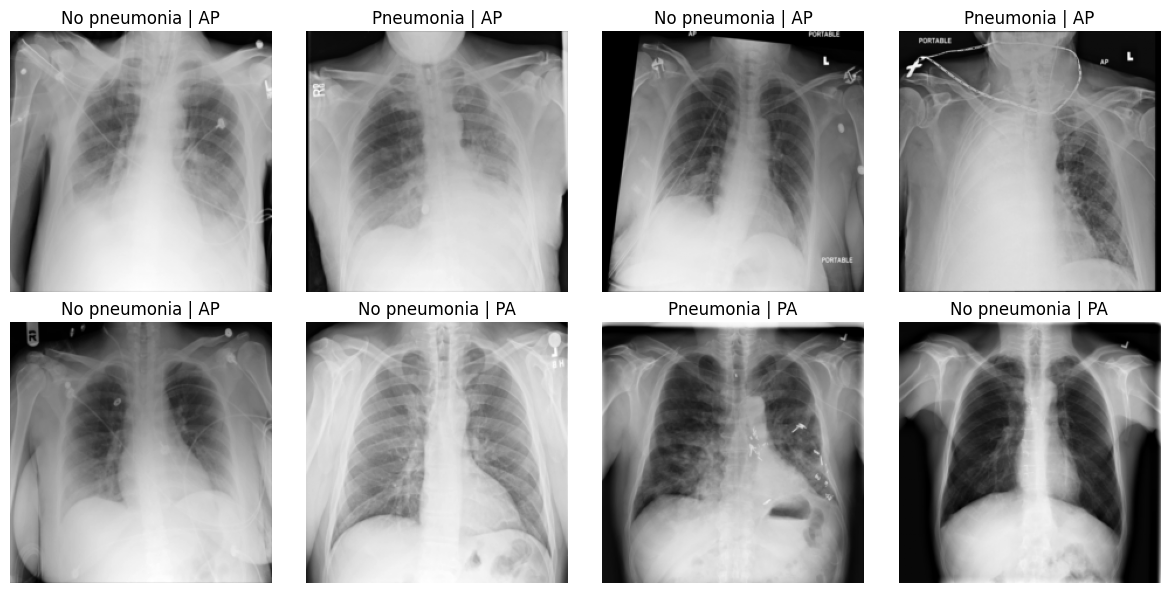

In [5]:
import matplotlib.pyplot as plt

idx = split[split['split'] == 'train'].sample(8, random_state=0).index
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(images[i], cmap='gray')
    ax.set_title(f"{'Pneumonia' if split.loc[i,'target'] else 'No pneumonia'} | {split.loc[i,'view']}")
    ax.axis('off')
plt.tight_layout()
plt.show()

In [6]:
#separating the 3 sets
y = split['target'].values
tr = split['split'].values == 'train'
va = split['split'].values == 'val'
te = split['split'].values == 'test'

X_tr, y_tr = images[tr], y[tr]
X_va, y_va = images[va], y[va]
X_te, y_te = images[te], y[te]

print("Train:", X_tr.shape, "| Val:", X_va.shape, "| Test:", X_te.shape)

Train: (5688, 224, 224) | Val: (1442, 224, 224) | Test: (1869, 224, 224)


In [7]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

def evaluate(name, y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)    # probability -> 0 or 1
    return {"model": name,
            "accuracy":  accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred),
            "recall":    recall_score(y_true, pred),
            "f1":        f1_score(y_true, pred),
            "auc":       roc_auc_score(y_true, prob)}

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def small_flat(x):
    return tf.image.resize(x[..., None], (64, 64)).numpy().reshape(len(x), -1) / 255.0

baseline = make_pipeline(StandardScaler(),
                         LogisticRegression(C=0.01, class_weight='balanced', max_iter=2000))
baseline.fit(small_flat(X_tr), y_tr)

prob_va_base = baseline.predict_proba(small_flat(X_va))[:, 1]
results = [evaluate("Baseline: logistic regression", y_va, prob_va_base)]
pd.DataFrame(results).round(3)

,model,accuracy,precision,recall,f1,auc
0,Baseline: logistic regression,0.696,0.492,0.621,0.549,0.734


In [9]:
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications.densenet import DenseNet121, preprocess_input

BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

augment = keras.Sequential([
    layers.RandomRotation(0.02),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.05, 0.05),
], name="augmentation")

def to_rgb(x, y):
    x = tf.cast(x, tf.float32)[..., None]
    x = tf.image.grayscale_to_rgb(x)
    return x, y

def make_ds(X, y, training):
    ds = tf.data.Dataset.from_tensor_slices((X, y)).map(to_rgb, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.shuffle(2000, seed=42)
    ds = ds.batch(BATCH)
    if training:
        ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_ds(X_tr, y_tr, training=True)
val_ds   = make_ds(X_va, y_va, training=False)

xb, yb = next(iter(train_ds))
print("Batch:", xb.shape, "| first labels:", yb.numpy()[:10])

Batch: (32, 224, 224, 3) | first labels: [1 1 1 1 1 1 1 1 1 1]


In [10]:
tf.keras.utils.set_random_seed(42)

base = DenseNet121(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
base.trainable = False

inputs  = keras.Input((224, 224, 3))
x       = base(inputs, training=False)
x       = layers.GlobalAveragePooling2D()(x)
x       = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation='sigmoid')(x)
model   = keras.Model(inputs, outputs)

model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss='binary_crossentropy',
              metrics=[keras.metrics.AUC(name='auc'), 'accuracy'])

n_train = sum(np.prod(w.shape) for w in model.trainable_weights)
print(f"Total parameters: {model.count_params():,} | trainable now: {n_train:,}")

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total parameters: 7,038,529 | trainable now: 1,025


In [11]:
from sklearn.utils.class_weight import compute_class_weight

cw = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_tr)
class_weight = {0: cw[0], 1: cw[1]}
print("Class weights:", class_weight)

history1 = model.fit(train_ds, validation_data=val_ds, epochs=5, class_weight=class_weight)

Class weights: {0: np.float64(0.7245859872611465), 1: np.float64(1.6131593874078276)}
Epoch 1/5
178/178 ━━━━━━━━━━━━━━━━━━━━ 255s 1s/step - accuracy: 0.7111 - auc: 0.7687 - loss: 0.6084 - val_accuracy: 0.7448 - val_auc: 0.7680 - val_loss: 0.5211
Epoch 2/5
178/178 ━━━━━━━━━━━━━━━━━━━━ 104s 431ms/step - accuracy: 0.7525 - auc: 0.8161 - loss: 0.5468 - val_accuracy: 0.7510 - val_auc: 0.7872 - val_loss: 0.5110
Epoch 3/5
178/178 ━━━━━━━━━━━━━━━━━━━━ 80s 421ms/step - accuracy: 0.7730 - auc: 0.8377 - loss: 0.5169 - val_accuracy: 0.7538 - val_auc: 0.7942 - val_loss: 0.5046
Epoch 4/5
178/178 ━━━━━━━━━━━━━━━━━━━━ 77s 423ms/step - accuracy: 0.7713 - auc: 0.8422 - loss: 0.5094 - val_accuracy: 0.7538 - val_auc: 0.7986 - val_loss: 0.4963
Epoch 5/5
178/178 ━━━━━━━━━━━━━━━━━━━━ 76s 419ms/step - accuracy: 0.7769 - auc: 0.8453 - loss: 0.5058 - val_accuracy: 0.7573 - val_auc: 0.8004 - val_loss: 0.4950


In [12]:
base.trainable = True
start = [l.name for l in base.layers].index('conv5_block1_0_bn')
for layer in base.layers[:start]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss='binary_crossentropy',
              metrics=[keras.metrics.AUC(name='auc'), 'accuracy'])

n_train = sum(np.prod(w.shape) for w in model.trainable_weights)
print(f"Trainable now: {n_train:,} of {model.count_params():,}")

Trainable now: 2,130,945 of 7,038,529


In [13]:
callbacks = [
    keras.callbacks.ModelCheckpoint(f'{OUT}/densenet121_best.keras', monitor='val_auc',
                                    mode='max', save_best_only=True, verbose=1),
    keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=4,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2,
                                      min_lr=1e-7, verbose=1),
]

history2 = model.fit(train_ds, validation_data=val_ds,
                     epochs=20, initial_epoch=5,
                     class_weight=class_weight, callbacks=callbacks)

Epoch 6/20
178/178 ━━━━━━━━━━━━━━━━━━━━ 0s 578ms/step - accuracy: 0.7452 - auc: 0.8486 - loss: 0.5546
Epoch 6: val_auc improved from None to 0.80494, saving model to /content/drive/MyDrive/pneumonia-project/results_03/densenet121_best.keras

Epoch 6: finished saving model to /content/drive/MyDrive/pneumonia-project/results_03/densenet121_best.keras
178/178 ━━━━━━━━━━━━━━━━━━━━ 201s 748ms/step - accuracy: 0.7767 - auc: 0.8539 - loss: 0.4759 - val_accuracy: 0.7601 - val_auc: 0.8049 - val_loss: 0.4951 - learning_rate: 1.0000e-05
Epoch 7/20
178/178 ━━━━━━━━━━━━━━━━━━━━ 0s 408ms/step - accuracy: 0.7060 - auc: 0.8096 - loss: 0.6305
Epoch 7: val_auc improved from 0.80494 to 0.80845, saving model to /content/drive/MyDrive/pneumonia-project/results_03/densenet121_best.keras

Epoch 7: finished saving model to /content/drive/MyDrive/pneumonia-project/results_03/densenet121_best.keras
178/178 ━━━━━━━━━━━━━━━━━━━━ 81s 447ms/step - accuracy: 0.7597 - auc: 0.8391 - loss: 0.4969 - val_accuracy: 0.7614

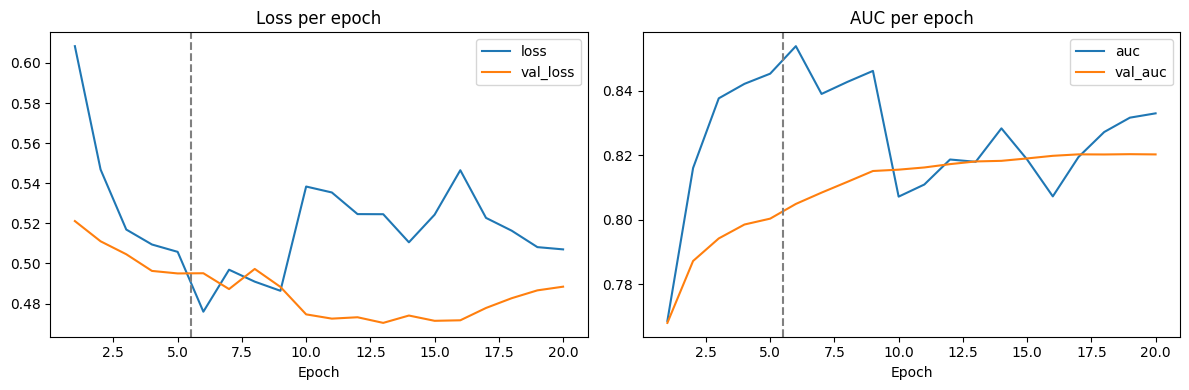

In [14]:
hist = pd.concat([pd.DataFrame(history1.history), pd.DataFrame(history2.history)],
                 ignore_index=True)
hist.index = hist.index + 1
hist.to_csv(f'{OUT}/training_history.csv', index_label='epoch')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
hist[['loss', 'val_loss']].plot(ax=axes[0], title='Loss per epoch')
hist[['auc', 'val_auc']].plot(ax=axes[1], title='AUC per epoch')
for ax in axes:
    ax.axvline(5.5, color='gray', linestyle='--')
    ax.set_xlabel('Epoch')
plt.tight_layout()
plt.savefig(f'{OUT}/figures/03_training_curves.png', dpi=300, bbox_inches='tight')
plt.show()

,model,accuracy,precision,recall,f1,auc
0,Baseline: logistic regression,0.696,0.492,0.621,0.549,0.734
1,CNN: DenseNet121,0.752,0.571,0.670,0.617,0.820


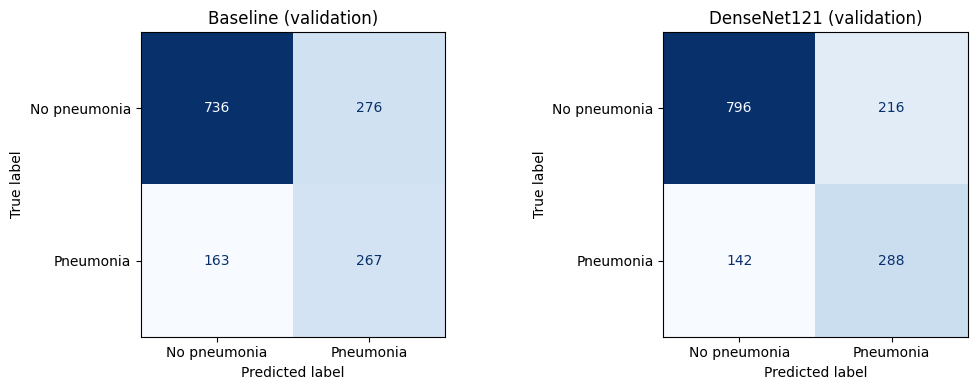

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

prob_va_cnn = model.predict(val_ds, verbose=0).ravel()
results.append(evaluate("CNN: DenseNet121", y_va, prob_va_cnn))
display(pd.DataFrame(results).round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, prob) in zip(axes, [("Baseline", prob_va_base), ("DenseNet121", prob_va_cnn)]):
    ConfusionMatrixDisplay.from_predictions(
        y_va, (prob >= 0.5).astype(int),
        display_labels=['No pneumonia', 'Pneumonia'],
        ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f"{name} (validation)")
plt.tight_layout()
plt.savefig(f'{OUT}/figures/03_confusion_validation.png', dpi=300, bbox_inches='tight')
plt.show()

In [16]:
test_ds = make_ds(X_te, y_te, training=False)

prob_te_base = baseline.predict_proba(small_flat(X_te))[:, 1]
prob_te_cnn  = model.predict(test_ds, verbose=0).ravel()

test_results = pd.DataFrame([
    evaluate("Baseline: logistic regression", y_te, prob_te_base),
    evaluate("CNN: DenseNet121", y_te, prob_te_cnn),
]).round(3)
test_results.to_csv(f'{OUT}/test_results.csv', index=False)
display(test_results)

split[te].assign(prob_base=prob_te_base, prob_cnn=prob_te_cnn) \
         .to_csv(f'{OUT}/test_predictions.csv', index=False)
print("Saved test_results.csv and test_predictions.csv")

,model,accuracy,precision,recall,f1,auc
0,Baseline: logistic regression,0.724,0.556,0.642,0.596,0.773
1,CNN: DenseNet121,0.768,0.617,0.706,0.659,0.832


Saved test_results.csv and test_predictions.csv


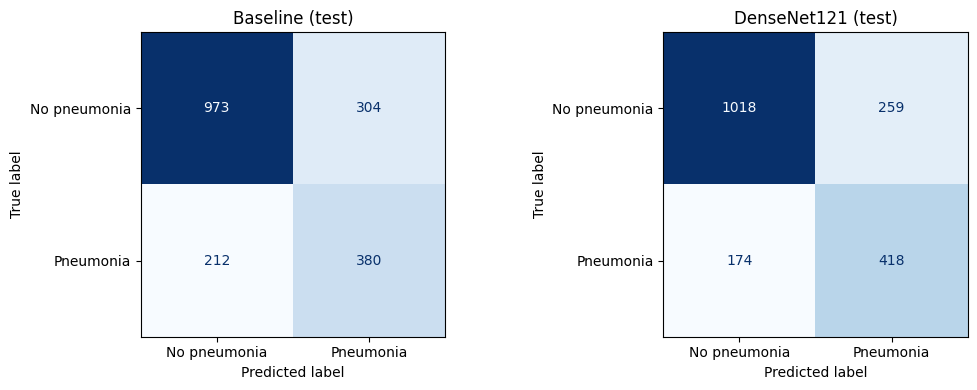

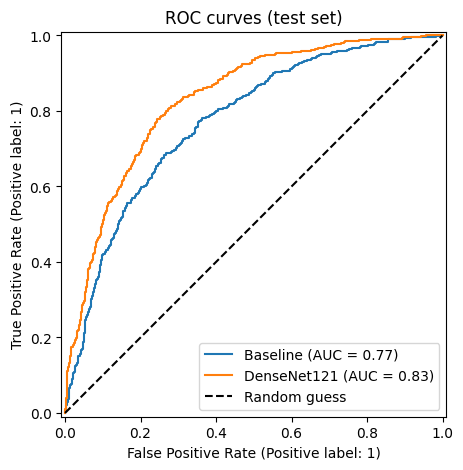

In [17]:
from sklearn.metrics import RocCurveDisplay

# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, prob) in zip(axes, [("Baseline", prob_te_base), ("DenseNet121", prob_te_cnn)]):
    ConfusionMatrixDisplay.from_predictions(
        y_te, (prob >= 0.5).astype(int),
        display_labels=['No pneumonia', 'Pneumonia'],
        ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f"{name} (test)")
plt.tight_layout()
plt.savefig(f'{OUT}/figures/03_confusion_test.png', dpi=300, bbox_inches='tight')
plt.show()

# ROC curves
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_te, prob_te_base, name='Baseline', ax=ax)
RocCurveDisplay.from_predictions(y_te, prob_te_cnn,  name='DenseNet121', ax=ax)
ax.plot([0, 1], [0, 1], 'k--', label='Random guess')
ax.set_title('ROC curves (test set)')
ax.legend()
plt.savefig(f'{OUT}/figures/03_roc_test.png', dpi=300, bbox_inches='tight')
plt.show()